# 02 · Training BaseNet and ArmNet

Trains the two MLPs, saves them (with their normalisation stats) and checks them offline.
Closed-loop testing in the simulator is done with `sim_runner.py`, not here.

**How to use:** set the options in the *Configuration* cell, then **Restart & Run All**.

| Option | Meaning |
|---|---|
| `DATASET` | `"clean"` → expert demos only (`processed_step10.npz`), `"noise"` → + noise-injected demos (`processed_step10_noise.npz`) |
| `USE_DAGGER` | add the DAgger runs (`data/dagger_r*/`) to the **ArmNet** training set |
| `TRAIN_BASE`, `TRAIN_ARM` | which network(s) to (re)train |
| `VERSION` | name of this model version; checkpoints are saved as `<net>_<VERSION>.pt` **and** as the active `<net>.pt` used by `policy.py` / `sim_runner.py` |

Model versions so far (test set, both networks driving, see `results/`):

| Version | ArmNet training data | @5 cm | @2 cm | @1 cm |
|---|---|---|---|---|
| `clean` | expert demos | arm unstable (flies) | – | – |
| `noise` | + noise injection | arm holds, never starts reaching | – | – |
| `dagger1` | + DAgger round 1 | reaches (≈1.2 cm on ep 9030) | – | – |
| `dagger2_cut` | + DAgger round 2 (runs cut too early) | 95.9 % | 66.3 % | 12.2 % |
| `dagger2_full` | + DAgger round 2 (full runs) | 94.9 % | 83.7 % | 10.2 % |

## Configuration

In [19]:
DATASET    = "noise"          # "clean" or "noise"
USE_DAGGER = True             # ArmNet only
TRAIN_BASE = False            # BaseNet already works -> only retrain when the base data changes
TRAIN_ARM  = True
GRAV_RES   = True             # ArmNet learns torque - g(q); policy.py adds g(q) back
VERSION    = "dagger4_gravres"   # name for the saved checkpoints

## Setup

In [20]:
%load_ext autoreload
%autoreload 2
import os, sys
import numpy as np
import torch
import matplotlib.pyplot as plt
torch.manual_seed(0); np.random.seed(0)
TASK_DIR = os.path.abspath("..")   # notebook runs from yousef/, so this is robotnik_arm_task/
RAW_DIR  = os.path.join(TASK_DIR, "data", "raw")
CKPT     = os.path.join(TASK_DIR, "checkpoints")
PROC     = os.path.join(TASK_DIR, "data", "processed_step10_noise.npz" if DATASET == "noise" else "processed_step10.npz")
sys.path.insert(0, os.path.join(TASK_DIR, "yousef"))

from models import MLP
from train import make_loaders, train_model
from dagger import add_dagger
from dataset import norm_stats

device = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs(CKPT, exist_ok=True)

D = dict(np.load(PROC))
print("dataset:", os.path.basename(PROC), "| base rows", D["Xb_train"].shape, "| arm rows", D["Xa_train"].shape, "|", device)
if GRAV_RES:                   # labels -> torque - g(q); stats recomputed on the expert train rows only
    for s in ["train", "val", "test"]:
        D[f"Ya_{s}"] = D[f"Ya_{s}"] - D[f"Ga_{s}"]
    D["Ya_mu"], D["Ya_sd"] = norm_stats(D["Ya_train"])
    print("gravity residual labels, Ya_mu:", D["Ya_mu"].round(2))
if USE_DAGGER:
    D = add_dagger(D, gravity_residual=GRAV_RES)   # appends DAgger rows to Xa_train / Ya_train only

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
dataset: processed_step10_noise.npz | base rows (1351543, 10) | arm rows (1351543, 25) | cuda
gravity residual labels, Ya_mu: [ 0.06  5.22  0.18 -1.35 -0.1   0.23 -0.08]
DAgger: 640 runs, 736984 arm rows
Xa_train now (2088527, 25)


## Helpers: save, evaluate in physical units, learned stiffness

In [21]:
def save_net(net, n, name):
    """n = "b" or "a". Saves weights + normalisation stats as <name>_<VERSION>.pt and as the active <name>.pt."""
    ck = {"state_dict": net.state_dict(),
          "in_dim": D[f"X{n}_mu"].shape[0], "out_dim": D[f"Y{n}_mu"].shape[0],
          "X_mu": D[f"X{n}_mu"], "X_sd": D[f"X{n}_sd"], "Y_mu": D[f"Y{n}_mu"], "Y_sd": D[f"Y{n}_sd"],
          "version": VERSION, "dataset": DATASET, "dagger": USE_DAGGER,
          "gravity_residual": GRAV_RES and n == "a"}
    torch.save(ck, os.path.join(CKPT, f"{name}_{VERSION}.pt"))
    torch.save(ck, os.path.join(CKPT, f"{name}.pt"))
    print(f"saved {name}_{VERSION}.pt and {name}.pt (active)")

def eval_physical(net, n, split="val"):
    """RMSE per output in physical units, overall and per expert phase (open loop, validation set)."""
    net.eval()
    x = (D[f"X{n}_{split}"] - D[f"X{n}_mu"]) / D[f"X{n}_sd"]
    with torch.no_grad():
        p = net(torch.from_numpy(x.astype(np.float32)).to(device)).cpu().numpy()
    err = (p * D[f"Y{n}_sd"] + D[f"Y{n}_mu"]) - D[f"Y{n}_{split}"]
    print("RMSE per output:", np.sqrt((err ** 2).mean(0)).round(4))
    for ph, name in enumerate(["align", "drive", "orient", "reaching"]):
        m = D[f"phase_{split}"] == ph
        print(f"  {name:9s} ({m.mean()*100:4.1f}% rows) RMSE:", np.sqrt((err[m] ** 2).mean(0)).round(4))

def plot_curves(hist, title):
    plt.figure(figsize=(5, 3.5))
    plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="val")
    plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE (normalised)"); plt.title(title); plt.legend(); plt.show()

## 1. BaseNet — 10 inputs → (v, ω)
Skipped unless `TRAIN_BASE = True`.

In [22]:
if TRAIN_BASE:
    train_dl, val_dl = make_loaders(D, "b")
    base_net, base_hist = train_model(MLP(10, 2), train_dl, val_dl, device=device)
    save_net(base_net, "b", "base_net")
    eval_physical(base_net, "b")          # v in m/s, omega in rad/s
    plot_curves(base_hist, f"BaseNet ({VERSION})")

## 2. ArmNet — 25 inputs → 7 torques

epoch  1 train 0.8055 val 0.1824 lr 1.0e-03
epoch  2 train 0.4018 val 0.1914 lr 1.0e-03
epoch  3 train 0.3118 val 0.1448 lr 1.0e-03
epoch  4 train 0.2617 val 0.1542 lr 1.0e-03
epoch  5 train 0.2290 val 0.1246 lr 1.0e-03
epoch  6 train 0.2052 val 0.1420 lr 1.0e-03
epoch  7 train 0.1863 val 0.1288 lr 1.0e-03
epoch  8 train 0.1717 val 0.1248 lr 1.0e-03
epoch  9 train 0.1599 val 0.1184 lr 1.0e-03
epoch 10 train 0.1489 val 0.1225 lr 1.0e-03
epoch 11 train 0.1390 val 0.1159 lr 1.0e-03
epoch 12 train 0.1306 val 0.1182 lr 1.0e-03
epoch 13 train 0.1247 val 0.1169 lr 1.0e-03
epoch 14 train 0.1192 val 0.1040 lr 1.0e-03
epoch 15 train 0.1136 val 0.1049 lr 1.0e-03
epoch 16 train 0.1086 val 0.1095 lr 1.0e-03
epoch 17 train 0.1044 val 0.1061 lr 1.0e-03
epoch 18 train 0.1015 val 0.1149 lr 1.0e-03
epoch 19 train 0.0976 val 0.1137 lr 1.0e-03
early stop
saved arm_net_dagger4_gravres.pt and arm_net.pt (active)
RMSE per output: [1.0719 0.82   1.0481 1.0052 1.0928 0.9037 0.2783]
  align     (16.2% rows) RMS

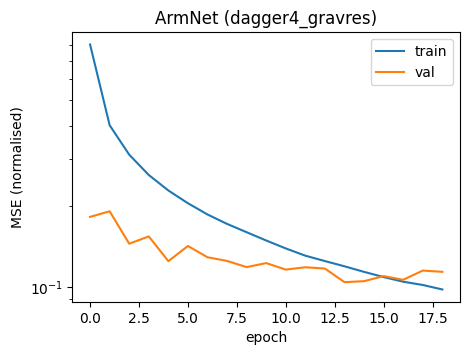

In [23]:
if TRAIN_ARM:
    train_dl, val_dl = make_loaders(D, "a")
    arm_net, arm_hist = train_model(MLP(25, 7), train_dl, val_dl, device=device)
    save_net(arm_net, "a", "arm_net")
    eval_physical(arm_net, "a")           # torques in N·m
    plot_curves(arm_hist, f"ArmNet ({VERSION})")

## 3. Learned joint stiffness and damping (diagnostic)

The expert holds the arm with τ = Kp(q_init − q) − Kd·q̇ + g(q), **Kp = 100, Kd = 30**.
A stable learned controller must react the same way: nudging joint j by 0.01 rad should change its torque by ≈ −1 N·m.
Values near 0 mean the network does not correct deviations → the arm drifts/swings in closed loop.

Result for the `clean` ArmNet (3 Nov): joints 3 and 6 had **≈ 0 stiffness** (joint 6 also ≈ 0 damping) → unstable.

In [24]:
from policy import BCPolicy

def stiffness_test(ep=9000, i=50):
    """Finite-difference dτ/dq and dτ/dq̇ of the ACTIVE checkpoints at a holding-phase state."""
    pol = BCPolicy(CKPT)
    e = np.load(os.path.join(RAW_DIR, f"ep_{ep:05d}.npz"))
    keys = ["base_pos", "base_bearing", "base_vel", "q_arm", "qd_arm", "ee_pos"]
    obs = {k: np.array(e[k][i], dtype=np.float64) for k in keys}; obs["target"] = e["target"]
    obs["tau_g"] = np.array(e["tau_g"][i])   # held fixed -> the test measures the feedback part only
    _, tau0 = pol(obs)
    for j in range(7):
        o = {k: v.copy() for k, v in obs.items()}; o["q_arm"][j] += 0.01
        _, tq = pol(o)
        o = {k: v.copy() for k, v in obs.items()}; o["qd_arm"][j] += 0.01
        _, tv = pol(o)
        print(f"joint {j+1}:  dτ/dq = {(tq[j]-tau0[j])/0.01:7.1f} (expert ≈ -100)   "
              f"dτ/dq̇ = {(tv[j]-tau0[j])/0.01:6.1f} (expert ≈ -30)")

stiffness_test()

joint 1:  dτ/dq =   -93.2 (expert ≈ -100)   dτ/dq̇ =  -29.4 (expert ≈ -30)
joint 2:  dτ/dq =   -96.1 (expert ≈ -100)   dτ/dq̇ =  -29.0 (expert ≈ -30)
joint 3:  dτ/dq =   -72.3 (expert ≈ -100)   dτ/dq̇ =  -24.3 (expert ≈ -30)
joint 4:  dτ/dq =   -75.4 (expert ≈ -100)   dτ/dq̇ =  -29.8 (expert ≈ -30)
joint 5:  dτ/dq =   -91.1 (expert ≈ -100)   dτ/dq̇ =  -25.3 (expert ≈ -30)
joint 6:  dτ/dq =   -16.5 (expert ≈ -100)   dτ/dq̇ =   -5.5 (expert ≈ -30)
joint 7:  dτ/dq =   -91.7 (expert ≈ -100)   dτ/dq̇ =  -16.5 (expert ≈ -30)
